<a href="https://colab.research.google.com/github/PARZIVAL283/CodeAlpha_Unemployment_Analysis_with_Python/blob/main/CodeAlpha_Unemployment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TASK 2: Unemployment Analysis with Python

# 1. import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


# 2. Dataset info

In [ ]:
df1 = pd.read_csv("/content/Unemployment in India.csv")
df2 = pd.read_csv("/content/Unemployment_Rate_upto_11_2020.csv")

print("Dataset 1 shape:", df1.shape)
print("\nDataset 1 columns:")
print(df1.columns.tolist())
print(df1.head())
print(df1.tail())


print("Dataset 2 shape:", df2.shape)
print("\nDataset 2 columns:")
print(df2.columns.tolist())
print(df1.head())
print(df1.tail())


Dataset 1 shape: (768, 7)

Dataset 1 columns:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']
           Region         Date  Frequency   Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-05-2019    Monthly                              3.65   
1  Andhra Pradesh   30-06-2019    Monthly                              3.05   
2  Andhra Pradesh   31-07-2019    Monthly                              3.75   
3  Andhra Pradesh   31-08-2019    Monthly                              3.32   
4  Andhra Pradesh   30-09-2019    Monthly                              5.17   

    Estimated Employed   Estimated Labour Participation Rate (%)   Area  
0           11999139.0                                     43.24  Rural  
1           11755881.0                                     42.05  Rural  
2           12086707.0                                     43.50  Rural  
3           12285693.0                

# 3. Dataset cleaning

In [ ]:
# Remove unnecessary spaces from column names
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# Remove completely empty rows
df1 = df1.dropna(how="all").copy()
df2 = df2.dropna(how="all").copy()

# Display actual dataset information
print("===== DATASET 1 =====")
print("Shape:", df1.shape)
print("Missing values:\n", df1.isnull().sum())
display(df1.head(3))
display(df1.tail(3))

print("\n===== DATASET 2 =====")
print("Shape:", df2.shape)
print("Missing values:\n", df2.isnull().sum())
display(df2.head(3))
display(df2.tail(3))

===== DATASET 1 =====
Shape: (740, 7)
Missing values:
 Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
751,West Bengal,30-04-2020,Monthly,15.63,9299466.0,41.20,Urban
752,West Bengal,31-05-2020,Monthly,15.22,9240903.0,40.67,Urban
753,West Bengal,30-06-2020,Monthly,9.86,9088931.0,37.57,Urban



===== DATASET 2 =====
Shape: (267, 9)
Missing values:
 Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
264,West Bengal,31-08-2020,M,14.87,33298644,47.48,East,22.9868,87.855
265,West Bengal,30-09-2020,M,9.35,35707239,47.73,East,22.9868,87.855
266,West Bengal,31-10-2020,M,9.98,33962549,45.63,East,22.9868,87.855


In [ ]:

# Convert dates to proper datetime format
for df in [df1, df2]:
    df["Date"] = pd.to_datetime(
        df["Date"].astype("string").str.strip(),
        format="%d-%m-%Y",
        errors="coerce"
    )

    # Convert important measurements to numeric values
    numeric_cols = [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]

    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dataset 1 date range:")
print(df1["Date"].min(), "to", df1["Date"].max())

print("\nDataset 2 date range:")
print(df2["Date"].min(), "to", df2["Date"].max())

print("\nDate conversion complete!")

Dataset 1 date range:
2019-05-31 00:00:00 to 2020-06-30 00:00:00

Dataset 2 date range:
2020-01-31 00:00:00 to 2020-10-31 00:00:00

Date conversion complete!


# Calculate monthly unemployment statistics

In [ ]:

# Remove rows missing essential analysis fields
df1_clean = df1.dropna(
    subset=["Date", "Region", "Estimated Unemployment Rate (%)"]).copy()

# Sort observations chronologically
df1_clean = df1_clean.sort_values("Date")

# Calculate average unemployment rate for each month
monthly_unemployment = (
    df1_clean.groupby("Date")["Estimated Unemployment Rate (%)"].mean().reset_index())

display(monthly_unemployment)
print("Number of monthly observations:", len(monthly_unemployment))

,Date,Estimated Unemployment Rate (%)
0,2019-05-31,8.874259
1,2019-06-30,9.303333
2,2019-07-31,9.033889
3,2019-08-31,9.637925
4,2019-09-30,9.051731
5,2019-10-31,9.900909
6,2019-11-30,9.868364
7,2019-12-31,9.497358
8,2020-01-31,9.950755
9,2020-02-29,9.964717


Number of monthly observations: 14


Visualize

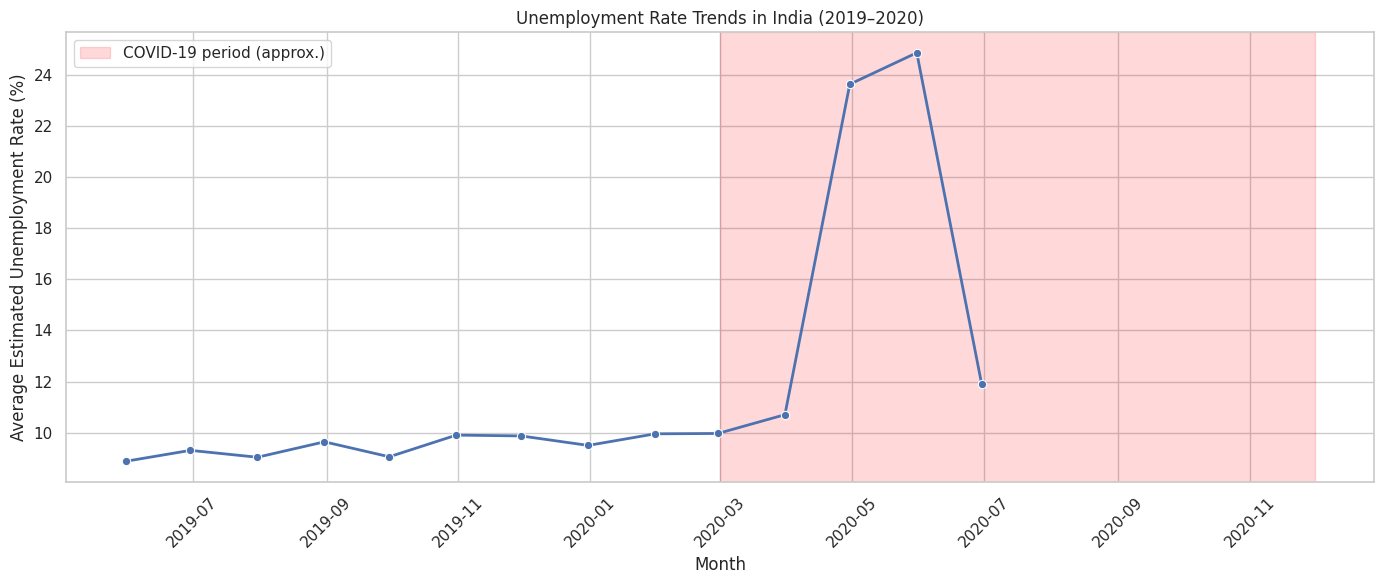

In [ ]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_unemployment,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o",
    linewidth=2
)

plt.axvspan(
    pd.Timestamp("2020-03-01"),
    pd.Timestamp("2020-12-01"),
    alpha=0.15,
    color="red",
    label="COVID-19 period (approx.)"
)

plt.title("Unemployment Rate Trends in India (2019–2020)")
plt.xlabel("Month")
plt.ylabel("Average Estimated Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# Highest-unemployment months

In [ ]:
top_months = monthly_unemployment.sort_values(
    by="Estimated Unemployment Rate (%)",
    ascending=False
).head(5)

print("Top 5 months by average unemployment rate:")
display(top_months)

Top 5 months by average unemployment rate:


,Date,Estimated Unemployment Rate (%)
12,2020-05-31,24.875294
11,2020-04-30,23.641569
13,2020-06-30,11.903600
10,2020-03-31,10.700577
9,2020-02-29,9.964717


# Compare urban and rural unemployment

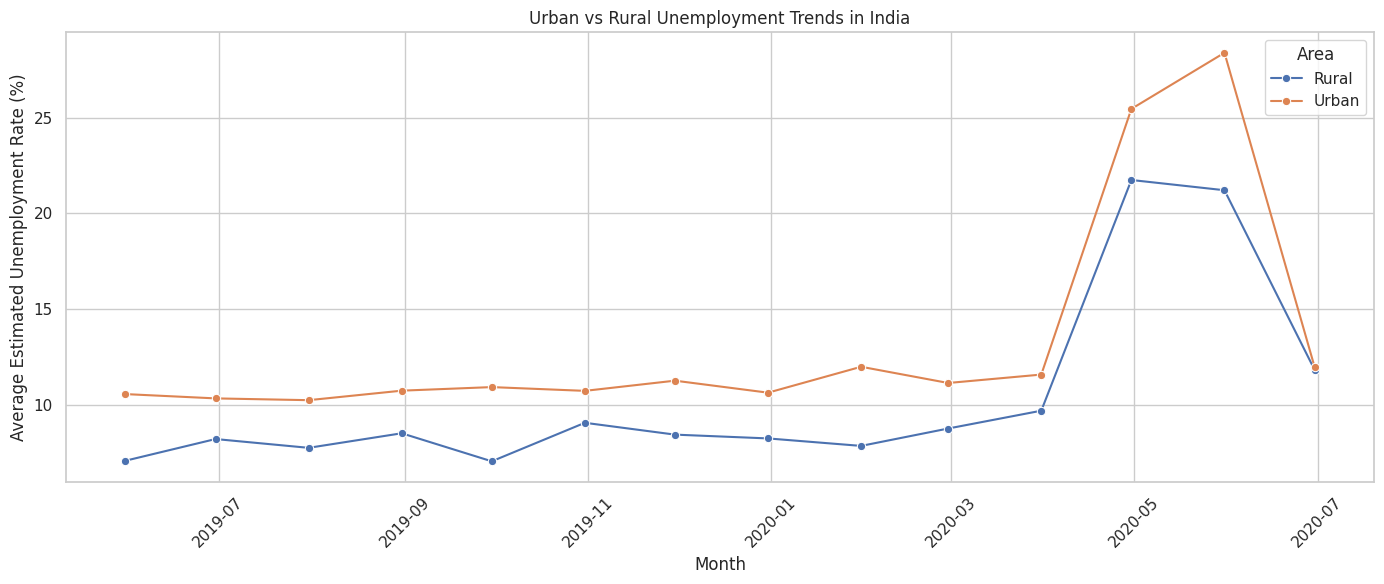

In [ ]:

area_unemployment = (
    df1_clean.groupby(["Date", "Area"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=area_unemployment,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Area",
    marker="o"
)

plt.title("Urban vs Rural Unemployment Trends in India")
plt.xlabel("Month")
plt.ylabel("Average Estimated Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Average unemployment rate by region

In [ ]:

# Calculate average unemployment rate for each region
regional_unemployment = (
    df1_clean.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

regional_unemployment.columns = [
    "Region",
    "Average Unemployment Rate (%)"
]

print("Top 10 regions by average unemployment rate:")
display(regional_unemployment.head(10))

print("Bottom 10 regions by average unemployment rate:")
display(regional_unemployment.tail(10))

Top 10 regions by average unemployment rate:


,Region,Average Unemployment Rate (%)
0,Tripura,28.350357
1,Haryana,26.283214
2,Jharkhand,20.585000
3,Bihar,18.918214
4,Himachal Pradesh,18.540357
5,Delhi,16.495357
6,Jammu & Kashmir,16.188571
7,Chandigarh,15.991667
8,Rajasthan,14.058214
9,Uttar Pradesh,12.551429


Bottom 10 regions by average unemployment rate:


,Region,Average Unemployment Rate (%)
18,Maharashtra,7.557500
19,Andhra Pradesh,7.477143
20,Madhya Pradesh,7.406429
21,Sikkim,7.249412
22,Karnataka,6.676071
23,Gujarat,6.663929
24,Uttarakhand,6.582963
25,Assam,6.428077
26,Odisha,5.657857
27,Meghalaya,4.798889


Visualize

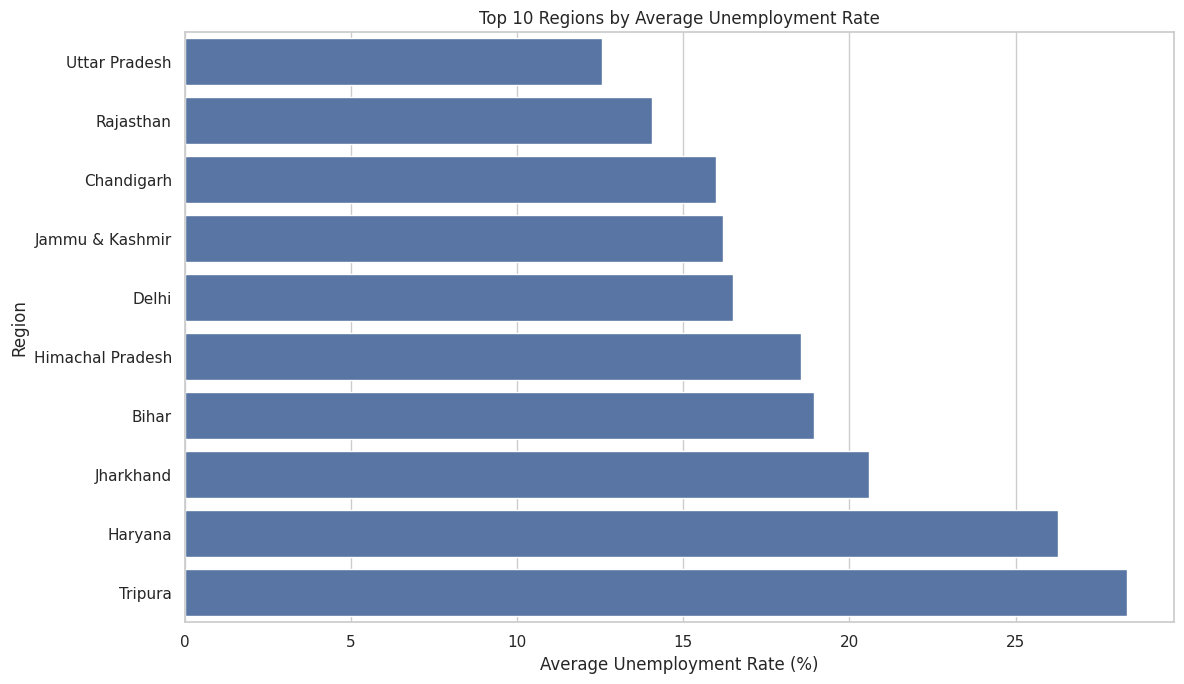

In [ ]:

top_10_regions = regional_unemployment.head(10).sort_values(
    "Average Unemployment Rate (%)"
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_regions,
    x="Average Unemployment Rate (%)",
    y="Region"
)

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

# Investigate the COVID-19 period

In [ ]:

# Create a period label
covid_df = df1_clean.copy()

covid_df["Period"] = np.where(
    covid_df["Date"] < pd.Timestamp("2020-03-01"),
    "Before COVID-19 (before Mar 2020)",
    "COVID-19 period (Mar 2020 onward)"
)

# Calculate average unemployment for each period
period_comparison = (
    covid_df.groupby("Period")["Estimated Unemployment Rate (%)"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

period_comparison.columns = [
    "Period",
    "Mean Unemployment Rate (%)",
    "Median Unemployment Rate (%)",
    "Number of Observations"
]

display(period_comparison)

,Period,Mean Unemployment Rate (%),Median Unemployment Rate (%),Number of Observations
0,Before COVID-19 (before Mar 2020),9.509534,7.115,536
1,COVID-19 period (Mar 2020 onward),17.774363,14.520,204


visualize

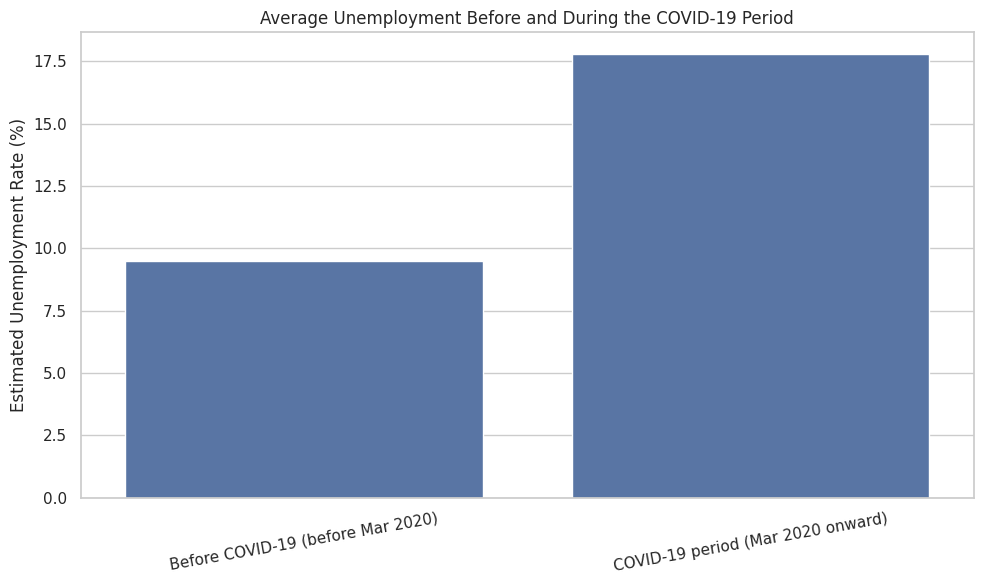

In [ ]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=covid_df,
    x="Period",
    y="Estimated Unemployment Rate (%)",
    errorbar=None
)

plt.title("Average Unemployment Before and During the COVID-19 Period")
plt.xlabel("")
plt.ylabel("Estimated Unemployment Rate (%)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# Compare unemployment across urban and rural areas

,Area,Period,Estimated Unemployment Rate (%)
0,Rural,Before COVID-19 (before Mar 2020),8.094808
1,Rural,COVID-19 period (Mar 2020 onward),16.181313
2,Urban,Before COVID-19 (before Mar 2020),10.842246
3,Urban,COVID-19 period (Mar 2020 onward),19.276381


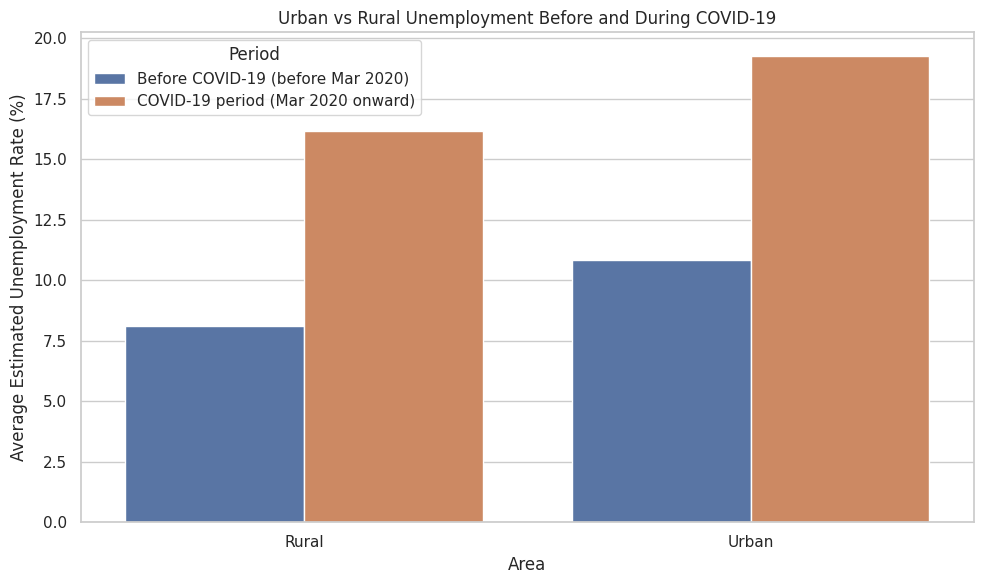

In [ ]:

area_period_comparison = (
    covid_df.groupby(["Area", "Period"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

display(area_period_comparison)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=area_period_comparison,
    x="Area",
    y="Estimated Unemployment Rate (%)",
    hue="Period"
)

plt.title("Urban vs Rural Unemployment Before and During COVID-19")
plt.xlabel("Area")
plt.ylabel("Average Estimated Unemployment Rate (%)")
plt.tight_layout()
plt.show()

# Monthly and seasonal patterns

In [ ]:

# Extract month information
seasonal_df = df1_clean.copy()
seasonal_df["Month"] = seasonal_df["Date"].dt.month
seasonal_df["Month Name"] = seasonal_df["Date"].dt.month_name()

# Calculate average unemployment for each calendar month
monthly_pattern = (
    seasonal_df.groupby(["Month", "Month Name"])
    ["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
    .sort_values("Month")
)

display(monthly_pattern)

,Month,Month Name,Estimated Unemployment Rate (%)
0,1,January,9.950755
1,2,February,9.964717
2,3,March,10.700577
3,4,April,23.641569
4,5,May,16.646190
5,6,June,10.553462
6,7,July,9.033889
7,8,August,9.637925
8,9,September,9.051731
9,10,October,9.900909


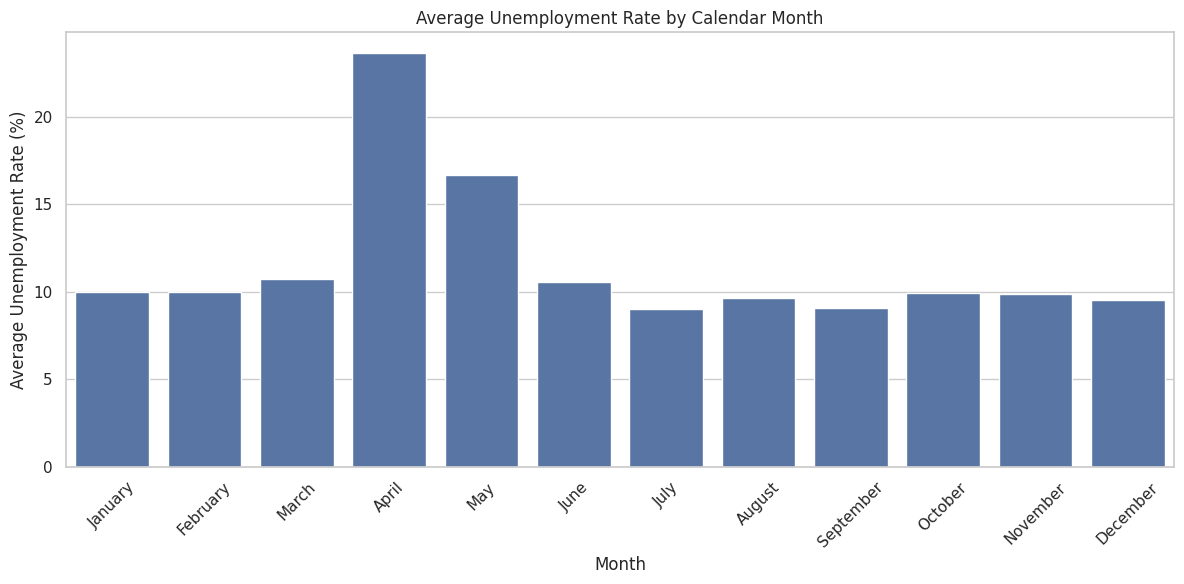

In [ ]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_pattern,
    x="Month Name",
    y="Estimated Unemployment Rate (%)"
)

plt.title("Average Unemployment Rate by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Correlation analysis

We'll examine three variables:

1. Estimated unemployment rate

2. Estimated number of employed people

3. Estimated labour participation rate

In [ ]:

correlation_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation_data = df1_clean[correlation_cols].dropna()

correlation_matrix = correlation_data.corr()

display(correlation_matrix)

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


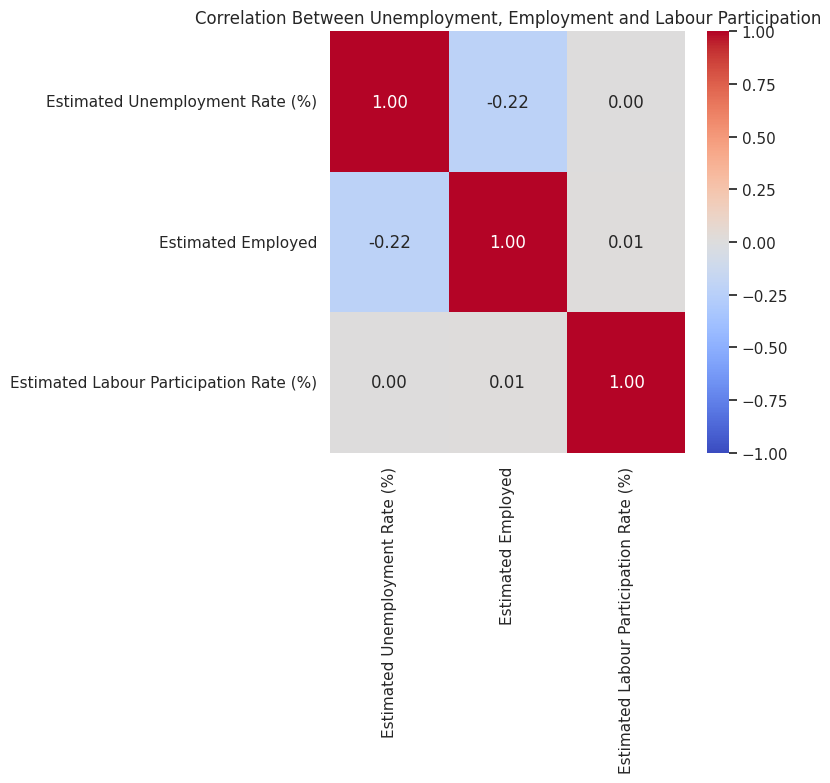

In [ ]:

plt.figure(figsize=(8,8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Unemployment, Employment and Labour Participation")
plt.tight_layout()
plt.show()

# Compare unemployment and labour participation

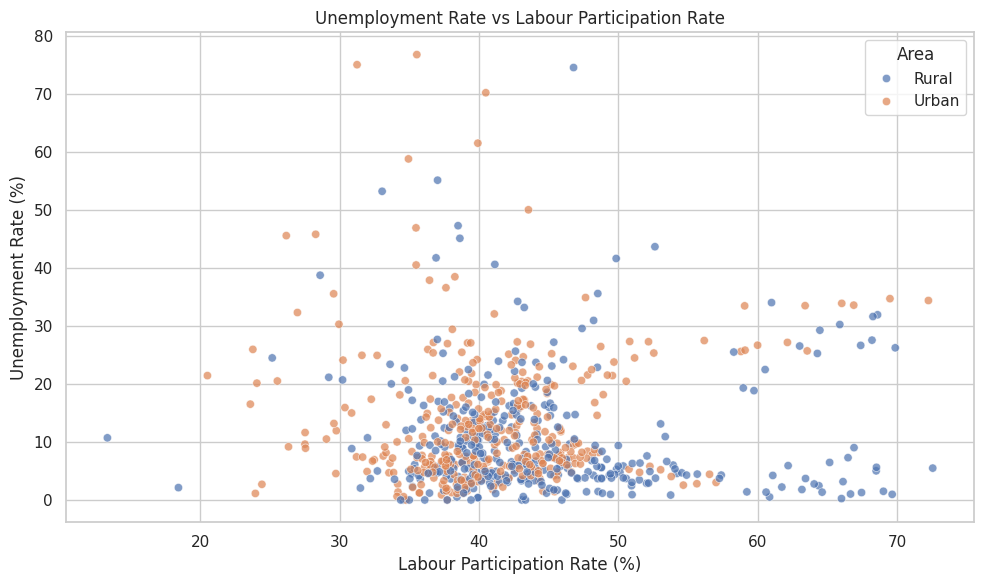

In [ ]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df1_clean,
    x="Estimated Labour Participation Rate (%)",
    y="Estimated Unemployment Rate (%)",
    hue="Area",
    alpha=0.7
)

plt.title("Unemployment Rate vs Labour Participation Rate")
plt.xlabel("Labour Participation Rate (%)")
plt.ylabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()

# key statistics for report

In [ ]:

print("========== KEY FINDINGS ==========")

print(
    "\nOverall average unemployment rate:",
    round(df1_clean["Estimated Unemployment Rate (%)"].mean(), 2),
    "%"
)

print(
    "\nHighest observed unemployment rate:",
    round(df1_clean["Estimated Unemployment Rate (%)"].max(), 2),
    "%"
)

print(
    "\nLowest observed unemployment rate:",
    round(df1_clean["Estimated Unemployment Rate (%)"].min(), 2),
    "%"
)

print("\nRegion with highest average unemployment:")
print(regional_unemployment.iloc[0])

print("\nRegion with lowest average unemployment:")
print(regional_unemployment.iloc[-1])

print("\nAverage unemployment by area:")
display(
    df1_clean.groupby("Area")["Estimated Unemployment Rate (%)"]
    .mean()
    .round(2)
)

========== KEY FINDINGS ==========

Overall average unemployment rate: 11.79 %

Highest observed unemployment rate: 76.74 %

Lowest observed unemployment rate: 0.0 %

Region with highest average unemployment:
Region                             Tripura
Average Unemployment Rate (%)    28.350357
Name: 0, dtype: object

Region with lowest average unemployment:
Region                           Meghalaya
Average Unemployment Rate (%)     4.798889
Name: 27, dtype: object

Average unemployment by area:


,Estimated Unemployment Rate (%)
Area,
Rural,10.32
Urban,13.17
